In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import scipy.sparse, os, warnings
warnings.simplefilter("ignore")
from glob import glob
from sklearn.metrics import mean_squared_error
import stan

In [2]:
sample_list = []
for x in glob('data/Ren_processed/*'):
    sample_list.append(x.split(r'/')[-1][:-5])
sample_list.sort()

sample_list

['Ren2', 'Ren3', 'Ren51']

In [3]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ren_processed/{sample}.h5ad")

In [4]:
data_list = []
for sample, adata in adatas.items():
    if scipy.sparse.issparse(adata.X):
        n_genes = adata.X.astype(bool).sum(axis=1).A1
    else:
        n_genes = (adata.X > 0).sum(axis=1)
    total_counts = adata.obs['n_counts'].copy()
    
    df = pd.DataFrame({
        'sample': sample,
        'n_genes': n_genes,
        'total_counts': total_counts
    })
    data_list.append(df)

df_all = pd.concat(data_list, ignore_index=True)

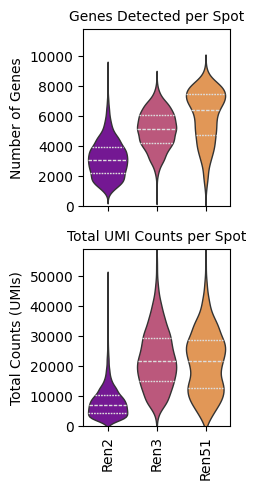

In [5]:
dpi = 300
fontsize = 8
figsize = 2.5

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(figsize*1, figsize*2), sharex=True)

sns.violinplot(
    data=df_all,
    x='sample',
    y='n_genes',
    ax=ax1,
    palette='plasma', 
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax1.set_title('Genes Detected per Spot', fontsize=10)
ax1.set_ylabel('Number of Genes')
# ax1.yaxis.grid(True)
ax1.set_ylim([0, 11800])


sns.violinplot(
    data=df_all,
    x='sample',
    y='total_counts',
    ax=ax2,
    palette='plasma',
    inner='quartile', linewidth=1,
    inner_kws={'color': '#DDDDDD'}
)
ax2.set_title('Total UMI Counts per Spot', fontsize=10)
ax2.set_ylabel('Total Counts (UMIs)')
ax2.set_xlabel('')
ax2.tick_params(axis='x', rotation=90)
# ax2.yaxis.grid(True)
ax2.set_ylim([0, 11800*5])

plt.tight_layout()
plt.savefig('plots_manuscript/qc_ren.pdf')
plt.show()

In [6]:
sample_means = df_all.groupby('sample').agg({
    'n_genes': 'mean',
    'total_counts': 'mean'
}).reset_index()
sample_means

,sample,n_genes,total_counts
0,Ren_GBM2,3186.359889,8159.175781
1,Ren_GBM3,5132.628604,22630.728516
2,Ren_GBM5_1,6036.108538,21510.681641


## Infer TF Activity
### Loading the TF-gene prior

In [7]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ren_processed/{sample}.h5ad")
    adatas[sample] = stan.add_gene_tf_matrix(adatas[sample],
                                            min_cells_proportion = 0.1,
                                            min_tfs_per_gene= 10,
                                            min_genes_per_tf= 5,
                                            gene_tf_source="hTFtarget",
                                            tf_list="humantfs",
                                            source_dir="resources/")

In [8]:
df_size = []
for sample in sample_list:
    D = adatas[sample].varm['gene_tf']
    Y = adatas[sample].to_df()
    df_size.append([D.shape[1], Y.shape[1], Y.shape[0],
                   D.T.abs().sum().min(),
                   D.abs().sum().min(),
                   (Y>0).sum().min(),
                   (Y>0).T.sum().min()])

df_size = pd.DataFrame(df_size, index=sample_list,
                      columns = ['TFs', 'Genes', 'Cells',
                                 'TFs_per_Gene', 'Genes_per_TF',
                                 'Cells_per_Gene', 'Genes_per_Cell'])
df_size

,TFs,Genes,Cells,TFs_per_Gene,Genes_per_TF,Cells_per_Gene,Genes_per_Cell
Ren_GBM2,233,7975,2887,10.0,5.0,289,609
Ren_GBM3,229,9530,1769,10.0,5.0,177,621
Ren_GBM5_1,248,10517,2202,10.0,5.0,221,702


### Computing the spatially dependent kernel

In [9]:
for sample in sample_list:
    stan.pixel_intensity(adatas[sample], windowsize=25)
    stan.make_kernel_from_pixel(adatas[sample], n=250, im_feats_weight=0.05)
    sc.pp.normalize_total(adatas[sample])
    adatas[sample].layers['scaled'] = np.sqrt(adatas[sample].to_df())

### Running STAN

In [10]:
df_corr = []
paras_dict_tfa = {}

for sample in sample_list:
    print(sample)
    stan.assign_folds(adatas[sample], n_folds=10, random_seed=0)
    stan_model = stan.Stan(adatas[sample], layer='scaled')
    stan_model.fit(n_steps=7, stages=1,
                  grid_search_params={'lam1':[1000],'lam2':[1e-3, 1e3]})
    paras_dict_tfa[sample] = stan_model.params

    cor = stan_model.evaluate(fold=-1)
    adatas[sample].obs['pred_cor_stan'] = cor
    adatas[sample].obsm['tfa_stan'] = pd.DataFrame(stan_model.W_concat.T, 
                                                    index=adatas[sample].obs_names, 
                                                    columns=adatas[sample].uns['tf_names'])
    
    Y = adatas[sample].varm['gene_tf'].dot(stan_model.W_concat)
    mse = mean_squared_error(Y, adatas[sample].to_df('scaled').T)
    df_corr.append([round(np.nanmean(cor), 4), mse])

df_corr = pd.DataFrame(df_corr, index=sample_list,columns = ['spot_corr', 'mse'])

Ren_GBM2
Time elapsed: 9.92 seconds
Ren_GBM3
Time elapsed: 6.06 seconds
Ren_GBM5_1
Time elapsed: 8.28 seconds


In [11]:
paras_dict_tfa

{'Ren_GBM2': {'lam2': 1.0, 'lam1': 1000},
 'Ren_GBM3': {'lam2': 0.01, 'lam1': 1000},
 'Ren_GBM5_1': {'lam2': 0.001, 'lam1': 1000}}

In [12]:
df_corr

,spot_corr,mse
Ren_GBM2,0.2293,0.537748
Ren_GBM3,0.2943,1.297991
Ren_GBM5_1,0.2359,1.089068


In [13]:
path = 'results'
if not os.path.exists(path):
    os.mkdir(path)
    
path = 'results/ren_tfa'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adatas[sample].write(f"{path}/{sample}.h5ad")

## Infer Pathway Activity
### Loading the pathway-gene prior

In [14]:
path2remove = ['HALLMARK_ADIPOGENESIS',
               'HALLMARK_MYOGENESIS',
               'HALLMARK_PANCREAS_BETA_CELLS',
               'HALLMARK_SPERMATOGENESIS',
               'HALLMARK_BILE_ACID_METABOLISM']

In [15]:
adatas = dict()
for sample in sample_list:
    adatas[sample] = sc.read_h5ad(f"data/Ren_processed/{sample}.h5ad")
    adatas[sample] = stan.add_gene_pw_matrix(adatas[sample],
                                             min_cells_proportion = 0.1,
                                             path2remove = path2remove,
                                             source_dir="resources/")

In [16]:
df_size = []
for sample in sample_list:
    D = adatas[sample].varm['gene_pw']
    Y = adatas[sample].to_df()
    df_size.append([D.shape[1], Y.shape[1], Y.shape[0],
                   D.T.abs().sum().min(),
                   D.abs().sum().min(),
                   (Y>0).sum().min(),
                   (Y>0).T.sum().min()])

df_size = pd.DataFrame(df_size, index=sample_list,
                      columns = ['Pathways', 'Genes', 'Cells',
                                 'PWs_per_Gene', 'Genes_per_PW',
                                 'Cells_per_Gene', 'Genes_per_Cell'])
df_size

,Pathways,Genes,Cells,PWs_per_Gene,Genes_per_PW,Cells_per_Gene,Genes_per_Cell
Ren_GBM2,45,2729,2887,1.0,21.0,289,259
Ren_GBM3,45,2985,1769,1.0,24.0,177,267
Ren_GBM5_1,45,3232,2202,1.0,27.0,222,316


### Computing the spatially dependent kernel

In [17]:
for sample in sample_list:
    stan.pixel_intensity(adatas[sample], windowsize=25)
    stan.make_kernel_from_pixel(adatas[sample], n=250, im_feats_weight=0.05)
    sc.pp.normalize_total(adatas[sample])
    adatas[sample].layers['scaled'] = np.sqrt(adatas[sample].to_df())

### Running STAN

In [18]:
df_corr = []
paras_dict_pwa = {}

for sample in sample_list:
    print(sample)
    stan.assign_folds(adatas[sample], n_folds=10, random_seed=0)
    stan_model = stan.Stan(adatas[sample], layer='scaled', prior='gene_pw')
    stan_model.fit(n_steps=7, stages=1,
                  grid_search_params={'lam1':[1000],'lam2':[1e-3, 1e3]})
    paras_dict_pwa[sample] = stan_model.params

    cor = stan_model.evaluate(fold=-1)
    adatas[sample].obs['pred_cor_stan'] = cor
    adatas[sample].obsm['pwa_stan'] = pd.DataFrame(stan_model.W_concat.T, 
                                                    index=adatas[sample].obs_names, 
                                                    columns=adatas[sample].uns['pw_names'])
    
    Y = adatas[sample].varm['gene_pw'].dot(stan_model.W_concat)
    mse = mean_squared_error(Y, adatas[sample].to_df('scaled').T)
    df_corr.append([round(np.nanmean(cor), 4), mse])
    
df_corr = pd.DataFrame(df_corr, index=sample_list, columns = ['spot_corr', 'mse'])

Ren_GBM2
Time elapsed: 5.10 seconds
Ren_GBM3
Time elapsed: 3.18 seconds
Ren_GBM5_1
Time elapsed: 3.94 seconds


In [19]:
paras_dict_pwa

{'Ren_GBM2': {'lam2': 0.001, 'lam1': 1000},
 'Ren_GBM3': {'lam2': 0.001, 'lam1': 1000},
 'Ren_GBM5_1': {'lam2': 0.001, 'lam1': 1000}}

In [20]:
df_corr  

,spot_corr,mse
Ren_GBM2,0.1708,0.733778
Ren_GBM3,0.2158,1.579968
Ren_GBM5_1,0.2139,1.514558


In [21]:
path = 'results/ren_pwa'
if not os.path.exists(path):
    os.mkdir(path)
    
for sample in sample_list:
    adatas[sample].write(f"{path}/{sample}.h5ad")